# 04. RFM 人群分层

**RFM 模型三个核心指标**：
- **R (Recency)**：最近一次消费距今天数 → **越小越好**（最近买过）
- **F (Frequency)**：消费频次（订单数） → **越大越好**
- **M (Monetary)**：总消费金额 → **越大越好**

**本 notebook 做什么**：
1. 以数据集最后一天的次日作为 "快照日期"
2. 对每个客户算 R/F/M 三个数
3. 分别用五分位（quintile）打 1-5 分
4. 根据 R、F、M 的组合规则，把客户分成 **高价值 / 潜力 / 沉睡 / 流失** 四群
5. 可视化每群画像
6. 导出 `customer_segments.csv`——这是最终业务交付物

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
sns.set_style('whitegrid')

df = pd.read_pickle('../data/retail_clean.pkl')
print('读入形状:', df.shape)

读入形状: (779425, 14)


## 1. 计算 RFM 三个指标

In [2]:
# 快照日期：数据集最后一天 + 1
snapshot_date = df['InvoiceDate'].max() + timedelta(days=1)
print('快照日期:', snapshot_date)

rfm = df.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

print('\nRFM 表形状:', rfm.shape)
print('\nRFM 描述统计:')
rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2)

快照日期: 2011-12-10 12:50:00

RFM 表形状: (5878, 4)

RFM 描述统计:


,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,201.33,6.29,2955.90
std,209.34,13.01,14440.85
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,2248.30
max,739.00,398.00,580987.04


In [3]:
rfm.head(10)

,Customer ID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,4921.53
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40
5,12351,375,1,300.93
6,12352,36,10,2849.84
7,12353,204,2,406.76
8,12354,232,1,1079.40
9,12355,214,2,947.61


## 2. 五分位打分（1-5）

- R 反向：天数越小，分数越高（最近买过的 = 5 分）
- F 正向：次数越大，分数越高
- M 正向：金额越大，分数越高

In [4]:
# R 反向：qcut 后标签反过来
rfm['R_score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)

# F 和 M 正向。F 有重复值（很多客户都只下 1 单），用 rank(method='first') 平滑
rfm['F_score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm['RFM_score'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score
0,12346,326,12,77556.46,2,5,5,255
1,12347,2,8,4921.53,5,4,5,545
2,12348,75,5,2019.40,3,4,4,344
3,12349,19,4,4428.69,5,3,5,535
4,12350,310,1,334.40,2,1,2,212


## 3. 定义四群

**分群规则**（面试讲得清楚的简化版）：

| 群组 | 条件 | 业务含义 |
|---|---|---|
| **高价值** | R≥4 且 F≥4 且 M≥4 | 近期活跃、高频、高金额——金主，重点维护 |
| **潜力** | R≥4 且 (F<4 或 M<4) | 近期活跃但金额/频次不高——重点培育、推品升级 |
| **沉睡** | R≤3 且 (F≥3 或 M≥3) | 曾经不错但最近不来——召回触达 |
| **流失** | R≤2 且 F≤2 且 M≤2 | 久未消费、金额小——低成本唤醒或放弃 |
| **其他** | 不满足以上任何条件 | 中间地带，常规维系 |

In [5]:
def segment(row):
    r, f, m = row['R_score'], row['F_score'], row['M_score']
    if r >= 4 and f >= 4 and m >= 4:
        return '高价值'
    elif r >= 4 and (f < 4 or m < 4):
        return '潜力'
    elif r <= 3 and (f >= 3 or m >= 3):
        return '沉睡'
    elif r <= 2 and f <= 2 and m <= 2:
        return '流失'
    else:
        return '其他'

rfm['Segment'] = rfm.apply(segment, axis=1)

# 每群人数和销售额贡献
seg_summary = rfm.groupby('Segment').agg(
    客户数=('Customer ID', 'count'),
    平均R=('Recency', 'mean'),
    平均F=('Frequency', 'mean'),
    平均M=('Monetary', 'mean'),
    总销售额=('Monetary', 'sum'),
).round(2)

seg_summary['客户占比'] = (seg_summary['客户数'] / seg_summary['客户数'].sum() * 100).round(2).astype(str) + '%'
seg_summary['销售额占比'] = (seg_summary['总销售额'] / seg_summary['总销售额'].sum() * 100).round(2).astype(str) + '%'

# 按业务重要性排序
order = ['高价值', '潜力', '沉睡', '其他', '流失']
seg_summary = seg_summary.reindex([x for x in order if x in seg_summary.index])
seg_summary

,客户数,平均R,平均F,平均M,总销售额,客户占比,销售额占比
Segment,,,,,,,
高价值,1297,19.96,17.11,9143.86,11859591.50,22.07%,68.26%
潜力,1067,25.94,2.85,971.25,1036324.31,18.15%,5.96%
沉睡,1955,256.52,5.05,2084.33,4074861.61,33.26%,23.45%
其他,279,108.24,1.24,287.25,80143.74,4.75%,0.46%
流失,1280,467.32,1.19,253.03,323883.11,21.78%,1.86%


## 4. 可视化：人群画像三连图

C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_2080\2717054033.py:37: UserWarning: Glyph 39640 (\N{CJK UNIFIED IDEOGRAPH-9AD8}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_2080\2717054033.py:37: UserWarning: Glyph 20215 (\N{CJK UNIFIED IDEOGRAPH-4EF7}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_2080\2717054033.py:37: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_2080\2717054033.py:37: UserWarning: Glyph 28508 (\N{CJK UNIFIED IDEOGRAPH-6F5C}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_2080\2717054033.py:37: UserWarning: Glyph 21147 (\N{CJK UNIFIED IDEOGRAPH-529B}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_2080\2717054033.py:37: UserWarning: Glyph 27785 (\N{CJK UNIFIE

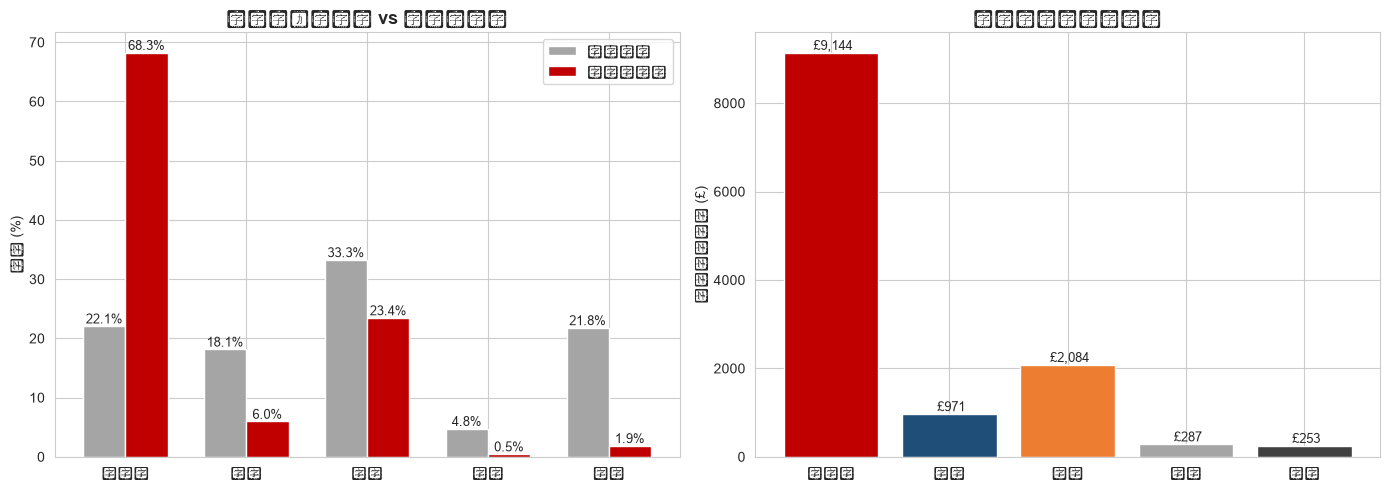

In [6]:
palette = {
    '高价值': '#C00000',
    '潜力': '#1F4E79',
    '沉睡': '#ED7D31',
    '其他': '#A5A5A5',
    '流失': '#404040',
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 左图：客户数 vs 销售额贡献 对比
idx = seg_summary.index.tolist()
x = np.arange(len(idx))
width = 0.35
cust_pct = [float(s.rstrip('%')) for s in seg_summary['客户占比']]
sales_pct = [float(s.rstrip('%')) for s in seg_summary['销售额占比']]

axes[0].bar(x - width/2, cust_pct, width, label='客户占比', color='#A5A5A5')
axes[0].bar(x + width/2, sales_pct, width, label='销售额占比', color='#C00000')
axes[0].set_xticks(x)
axes[0].set_xticklabels(idx)
axes[0].set_ylabel('占比 (%)')
axes[0].set_title('各人群：客户数 vs 销售额贡献', fontsize=13, fontweight='bold')
axes[0].legend()
for i, (c, s) in enumerate(zip(cust_pct, sales_pct)):
    axes[0].text(i - width/2, c, f'{c:.1f}%', ha='center', va='bottom', fontsize=9)
    axes[0].text(i + width/2, s, f'{s:.1f}%', ha='center', va='bottom', fontsize=9)

# 右图：各群平均 Monetary（金额感）
colors = [palette[seg] for seg in idx]
axes[1].bar(idx, seg_summary['平均M'], color=colors)
axes[1].set_ylabel('人均消费金额 (£)')
axes[1].set_title('各人群人均消费金额', fontsize=13, fontweight='bold')
for i, v in enumerate(seg_summary['平均M']):
    axes[1].text(i, v, f' £{v:,.0f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('../outputs/07_rfm_segments.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. R-F 热力图

**最经典的 RFM 可视化**：行是 R 分，列是 F 分，格子颜色表示人数。能一眼看出用户集中在哪些格子。

D:\projects\kaggle-ecommerce\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 23458 (\N{CJK UNIFIED IDEOGRAPH-5BA2}) missing from font(s) Arial.
  fig.canvas.draw()
D:\projects\kaggle-ecommerce\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 25143 (\N{CJK UNIFIED IDEOGRAPH-6237}) missing from font(s) Arial.
  fig.canvas.draw()
D:\projects\kaggle-ecommerce\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_2080\3785926046.py:10: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_2080\3785926046.py:10: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Yeungfong\AppData\Local\Temp\ipykernel_2080\3785926046.py:10: UserWarning: Glyph 26368 (\N{CJK 

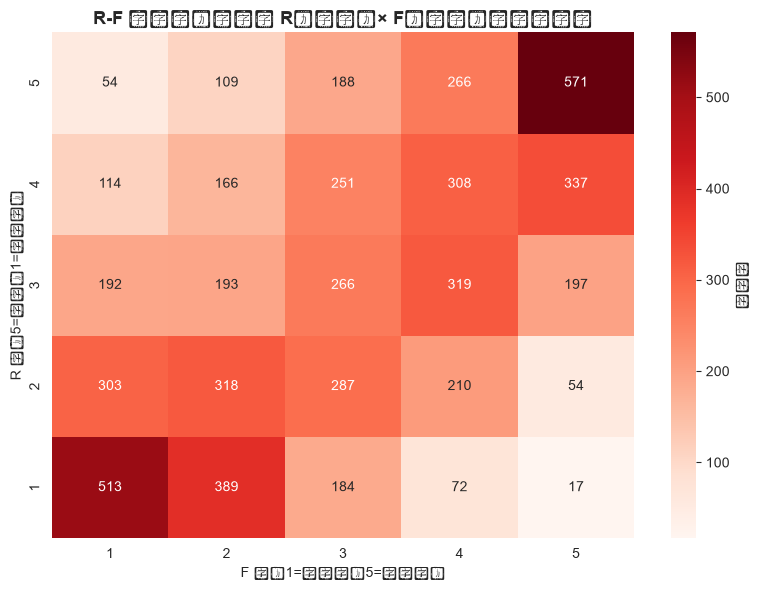

In [7]:
rf_pivot = rfm.pivot_table(index='R_score', columns='F_score', values='Customer ID', aggfunc='count', fill_value=0)
# R 从 5（最近）到 1（最远），顶部是"最近"
rf_pivot = rf_pivot.sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(rf_pivot, annot=True, fmt='d', cmap='Reds', ax=ax, cbar_kws={'label': '客户数'})
ax.set_title('R-F 热力图：客户在 R（最近）× F（频次）网格的分布', fontsize=13, fontweight='bold')
ax.set_xlabel('F 分（1=最低频，5=最高频）')
ax.set_ylabel('R 分（5=最近，1=最久远）')
plt.tight_layout()
plt.savefig('../outputs/08_rf_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. 导出：人群分层明细 CSV

这个 CSV 就是最终的"业务交付物"——相当于把 Customer ID 分到不同人群，供推广投放系统圈选使用。

In [8]:
export_cols = ['Customer ID', 'Recency', 'Frequency', 'Monetary',
               'R_score', 'F_score', 'M_score', 'RFM_score', 'Segment']

rfm[export_cols].to_csv('../outputs/customer_segments.csv', index=False, encoding='utf-8-sig')
seg_summary.to_csv('../outputs/segment_summary.csv', encoding='utf-8-sig')

print('已导出:')
print('  ../outputs/customer_segments.csv （客户级明细）')
print('  ../outputs/segment_summary.csv （人群汇总）')
print(f'\n明细行数: {len(rfm)}')
rfm[export_cols].head(10)

已导出:
  ../outputs/customer_segments.csv （客户级明细）
  ../outputs/segment_summary.csv （人群汇总）

明细行数: 5878


,Customer ID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,Segment
0,12346,326,12,77556.46,2,5,5,255,沉睡
1,12347,2,8,4921.53,5,4,5,545,高价值
2,12348,75,5,2019.40,3,4,4,344,沉睡
3,12349,19,4,4428.69,5,3,5,535,潜力
4,12350,310,1,334.40,2,1,2,212,流失
5,12351,375,1,300.93,2,1,2,212,流失
6,12352,36,10,2849.84,4,5,4,454,高价值
7,12353,204,2,406.76,2,2,2,222,流失
8,12354,232,1,1079.40,2,1,3,213,沉睡
9,12355,214,2,947.61,2,2,3,223,沉睡


---

## 项目完成总结

**全流程**：
1. ✅ 原始数据 106.7 万行 → 清洗保留 77.9 万行（保留率 73%）
2. ✅ EDA 6 张图：销售趋势、国家分布、时间模式、客户长尾
3. ✅ RFM 建模：5878 名客户按 R/F/M 五分位打分
4. ✅ 分成 高价值 / 潜力 / 沉睡 / 流失 / 其他 五群
5. ✅ 导出 customer_segments.csv 供下游圈选使用

**核心业务洞察**（面试讲故事直接用）：
- Top 20% 客户贡献 77% 销售额（二八法则）
- UK 本土占 83%，但 10 月备货季海外订单显著拉升
- 周六订单几乎为 0 → B2B 批发商特征
- 27.6% 一次性客户 → 复购运营是重要增长点